# Ajedrez online · Las familias de modelos, corte por corte

**Proyecto Integrador · Ciencia de Datos, UTN FRM 2026**

**Pregunta.** El notebook 04 eligió el random forest comparando cuatro familias con la log-loss **promediada sobre todos los cortes**. ¿Esa comparación vale en cada momento de la partida, o hay momentos (antes de mover, la apertura, el final) en los que otra familia predice mejor?

**Qué hay en este notebook.**

1. el planteo: qué se compara y con qué regla;
2. los datos: lo que predijo cada familia en cada pedazo de validación del 04, verificado contra el 04;
3. log-loss y accuracy de cada familia en cada corte;
4. la tabla por tramo de jugadas, con media y desvío de los cinco pedazos;
5. la diferencia pedazo a pedazo entre familias en cada tramo: ¿cambia la elección en algún tramo?;
6. la verificación;
7. las conclusiones.

**Qué no hay.** Ninguna decisión de modelado. El modelo de la app es el que dejó el notebook 04 (`models/modelo_en_vivo.joblib`); este notebook no entrena nada: lee `models/familias_por_pedazo.parquet`, que guarda la última sección del 04. Hace falta haber corrido antes el 04 con **Restart & Run All**.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.app_data import REPORTE_MODELADO, leer_reporte
from src.comparacion_familias import FAMILIAS_POR_PEDAZO, diferencia_pareada, media_y_desvio, metricas_por_pedazo
from src.metricas_tramo import TRAMOS
from src.utils import load_config

config = load_config(PROJECT_ROOT / "config" / "config.yaml")
REFERENCE_CUTS = config["live_prediction"]["cortes_referencia"]

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

FLOOR, SIMPLE = "Piso (prior)", "Regresión logística"
DEFAULTS = ["Random forest", "Gradient boosting"]
TUNED = ["Random forest ajustado", "Gradient boosting ajustado"]
MODELS = [FLOOR, SIMPLE, *DEFAULTS, *TUNED]
STYLE = {
    FLOOR: dict(color="#9e9e9e", linestyle="-"),
    SIMPLE: dict(color="#ed7d31", linestyle="-"),
    "Random forest": dict(color="#4472c4", linestyle="--"),
    "Gradient boosting": dict(color="#70ad47", linestyle="--"),
    "Random forest ajustado": dict(color="#4472c4", linestyle="-"),
    "Gradient boosting ajustado": dict(color="#70ad47", linestyle="-"),
}

## 1 · Planteo

**Qué se compara.** Las mismas familias de las secciones 3 y 5 del notebook 04, con las mismas filas, columnas y pedazos:

| Modelo | De dónde sale |
|---|---|
| Piso (prior) | §3: siempre las proporciones de train |
| Regresión logística | §3: el modelo simple, la referencia |
| Random forest, Gradient boosting | §3: valores por defecto (los que decidieron "ensamble sí o no") |
| Random forest ajustado, Gradient boosting ajustado | §5: la mejor configuración de la búsqueda aleatoria de cada uno (los que decidieron "bosque o boosting") |

Todos usan las columnas base del 04 (pre-partida + en vivo), que es con las que se compararon; el modelo final suma después las columnas de la §7 y la regla de mate. La muestra es la del 04: el 25 % de las partidas de train, con `TimeSeriesSplit` de 5 pedazos sobre las partidas ordenadas por inicio.

**Por qué con la validación cruzada y no con el test.** El test mide sólo el modelo elegido. Comparar familias en el test sería volver a elegir mirándolo. Además, la validación cruzada da cinco mediciones de cada familia, y con eso se puede decir si una diferencia es más grande que su variación.

**Cómo se mide.** En cada pedazo y en cada corte (o tramo) se calcula la métrica sobre las filas de validación; la tabla informa la media de los cinco pedazos ± su desvío, como la tabla de comparación del 04.

- **Log-loss**, la métrica declarada: cuánta probabilidad le dio el modelo a lo que pasó.
- **Accuracy**, la decisión fija: la clase más probable, ¿acertó? Más el F1 macro y el recall de tablas, que ven a la clase chica.

**La regla para comparar dos familias**, la misma del 04: en cada pedazo se resta la métrica de una menos la de la otra (mismas filas), y una "le gana" a la otra sólo si la diferencia media supera su desvío.

**Población.** En un corte dado, todas las familias predicen exactamente las mismas filas, así que la comparación **entre familias** dentro de un corte es justa. Lo que no es justo es comparar un corte con otro: en el ply 90 quedan otras partidas que en el 0. Esa comparación entre cortes, con población común e intervalos, está en el notebook 04 (§8, "Comparación entre cortes").

## 2 · Datos: lo que predijo cada familia en cada pedazo

Una fila por (modelo, pedazo, partida, corte) con las tres probabilidades. Antes de medir nada se verifica que reproduce el 04: la log-loss de cada pedazo de las familias de la §3 tiene que dar lo mismo que la tabla `comparacion_por_fold` del reporte, y la media de cada ensamble ajustado, lo mismo que su mejor candidato en la búsqueda de la §5. Si no coincide, el notebook falla.

In [2]:
pred = pd.read_parquet(PROJECT_ROOT / FAMILIAS_POR_PEDAZO)
pred["modelo"] = pred["modelo"].astype(str)
report = leer_reporte(PROJECT_ROOT / REPORTE_MODELADO)
CHOSEN = report["elegido"]
assert sorted(pred["modelo"].unique()) == sorted(MODELS), f"Faltan modelos: {sorted(pred['modelo'].unique())}"

# Every model predicts exactly the same validation rows.
keys = pred.groupby("modelo")[["fold", "GameUrl", "corte_ply"]].apply(lambda g: frozenset(map(tuple, g.to_numpy())))
assert keys.nunique() == 1, "Los modelos no predicen las mismas filas"

overall = metricas_por_pedazo(pred)
per_fold = overall.pivot(index="fold", columns="modelo", values="log_loss")
nb04_folds = pd.DataFrame(report["comparacion_por_fold"]).set_index("fold")
for name in [FLOOR, SIMPLE, *DEFAULTS]:
    gap = (per_fold[name] - nb04_folds[name]).abs().max()
    assert gap < 1e-9, f"{name}: la log-loss por pedazo difiere del notebook 04 en {gap:.2e}"
grid = pd.DataFrame(report["grilla"])
for name, family in zip(TUNED, DEFAULTS):
    best = grid.loc[grid["familia"] == family, "log_loss"].min()
    gap = abs(per_fold[name].mean() - best)
    assert gap < 1e-9, f"{name}: la media difiere de la búsqueda del notebook 04 en {gap:.2e}"

print(f"{pred['modelo'].nunique()} modelos × {len(pred) // pred['modelo'].nunique():,} filas de validación "
      f"({pred['GameUrl'].nunique():,} partidas, {pred['fold'].nunique()} pedazos, {pred['corte_ply'].nunique()} cortes)")
print(f"Coincide con el notebook 04. Modelo elegido ahí: {CHOSEN}")
display(media_y_desvio(overall).loc[MODELS])

6 modelos × 259,117 filas de validación (16,730 partidas, 5 pedazos, 25 cortes)
Coincide con el notebook 04. Modelo elegido ahí: Random forest


,log_loss,± log_loss,accuracy,± accuracy,f1_macro,± f1_macro,recall_empate,± recall_empate
modelo,,,,,,,,
Piso (prior),0.9379,0.0095,0.4666,0.0215,0.2120,0.0068,0.0000,0.0000
Regresión logística,0.8559,0.0274,0.5858,0.0173,0.4139,0.0101,0.0088,0.0052
Random forest,0.8375,0.0249,0.5949,0.0177,0.4184,0.0135,0.0066,0.0046
Gradient boosting,0.8676,0.0638,0.5830,0.0258,0.4474,0.0150,0.0795,0.0117
Random forest ajustado,0.8294,0.0264,0.5950,0.0163,0.4305,0.0193,0.0269,0.0172
Gradient boosting ajustado,0.8291,0.0329,0.5961,0.0196,0.4417,0.0209,0.0462,0.0177


## 3 · Corte por corte

La log-loss y la accuracy de cada familia en cada uno de los 25 cortes. La línea es la media de los cinco pedazos y la banda, ± un desvío. Las líneas cortadas son los ensambles con sus valores por defecto; las enteras, los ajustados.

Qué mirar: si las curvas se cruzan en algún momento, y si la distancia entre el bosque ajustado y el resto es más grande que el ancho de las bandas.

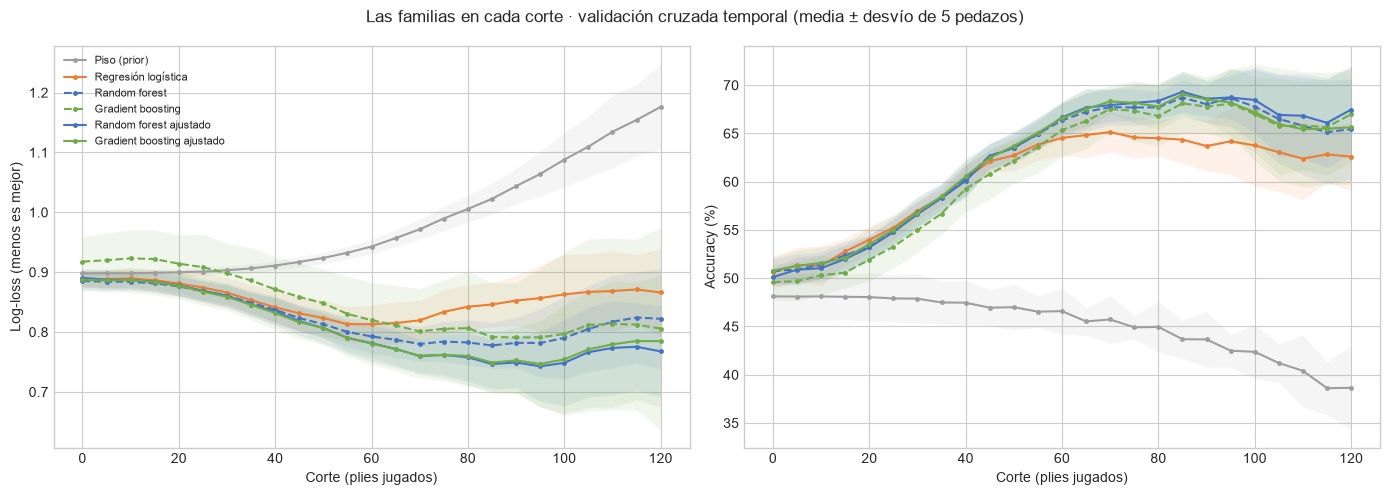

log_loss en los cortes de referencia (media ± desvío)


modelo,Piso (prior),Regresión logística,Random forest,Gradient boosting,Random forest ajustado,Gradient boosting ajustado
corte_ply,,,,,,
0,0.8980 ± 0.0059,0.8873 ± 0.0121,0.8853 ± 0.0140,0.9177 ± 0.0415,0.8903 ± 0.0144,0.8873 ± 0.0181
10,0.8982 ± 0.0059,0.8896 ± 0.0167,0.8841 ± 0.0144,0.9232 ± 0.0475,0.8871 ± 0.0149,0.8868 ± 0.0208
20,0.8998 ± 0.0065,0.8811 ± 0.0203,0.8763 ± 0.0166,0.9142 ± 0.0479,0.8783 ± 0.0176,0.8775 ± 0.0221
30,0.9032 ± 0.0069,0.8660 ± 0.0253,0.8610 ± 0.0168,0.8981 ± 0.0504,0.8606 ± 0.0194,0.8589 ± 0.0227
40,0.9110 ± 0.0080,0.8414 ± 0.0288,0.8373 ± 0.0210,0.8712 ± 0.0548,0.8342 ± 0.0230,0.8318 ± 0.0282
60,0.9428 ± 0.0123,0.8130 ± 0.0315,0.7926 ± 0.0282,0.8199 ± 0.0625,0.7814 ± 0.0302,0.7808 ± 0.0354
80,1.0056 ± 0.0225,0.8423 ± 0.0364,0.7826 ± 0.0377,0.8065 ± 0.0955,0.7578 ± 0.0397,0.7601 ± 0.0496
100,1.0879 ± 0.0450,0.8630 ± 0.0670,0.7902 ± 0.0688,0.7968 ± 0.1359,0.7485 ± 0.0719,0.7543 ± 0.0905
120,1.1760 ± 0.0719,0.8661 ± 0.0725,0.8222 ± 0.0836,0.8058 ± 0.1690,0.7677 ± 0.0760,0.7848 ± 0.1106


accuracy en los cortes de referencia (media ± desvío)


modelo,Piso (prior),Regresión logística,Random forest,Gradient boosting,Random forest ajustado,Gradient boosting ajustado
corte_ply,,,,,,
0,48.1 ± 2.4,50.6 ± 1.7,50.7 ± 1.3,49.6 ± 1.8,50.1 ± 0.9,50.8 ± 1.4
10,48.1 ± 2.4,51.3 ± 2.0,51.4 ± 1.4,50.3 ± 2.0,51.0 ± 1.4,51.6 ± 1.7
20,48.0 ± 2.5,54.0 ± 1.4,53.2 ± 1.2,51.9 ± 2.2,53.2 ± 1.2,53.5 ± 1.7
30,47.9 ± 2.6,57.0 ± 1.0,56.9 ± 1.5,55.0 ± 2.3,56.6 ± 1.3,56.8 ± 1.6
40,47.5 ± 2.3,60.4 ± 1.5,60.3 ± 1.9,59.3 ± 2.4,60.1 ± 1.7,60.5 ± 1.9
60,46.6 ± 2.4,64.5 ± 1.8,66.4 ± 1.7,65.4 ± 2.8,66.7 ± 1.6,66.6 ± 1.8
80,45.0 ± 2.6,64.5 ± 1.9,67.7 ± 1.6,66.8 ± 3.1,68.4 ± 1.8,67.8 ± 2.3
100,42.4 ± 2.8,63.8 ± 4.2,67.8 ± 3.8,67.0 ± 3.9,68.5 ± 3.4,67.2 ± 5.0
120,38.6 ± 4.3,62.6 ± 3.6,65.5 ± 5.2,67.0 ± 4.9,67.5 ± 4.5,65.6 ± 5.9


In [3]:
by_cut = metricas_por_pedazo(pred, "corte_ply")
summary_cut = media_y_desvio(by_cut, "corte_ply")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, ylabel, scale in [(axes[0], "log_loss", "Log-loss (menos es mejor)", 1),
                                  (axes[1], "accuracy", "Accuracy (%)", 100)]:
    for name in MODELS:
        s = summary_cut.loc[name]
        ax.plot(s.index, s[metric] * scale, marker="o", markersize=2.5, label=name, **STYLE[name])
        ax.fill_between(s.index, (s[metric] - s[f"± {metric}"]) * scale, (s[metric] + s[f"± {metric}"]) * scale,
                        color=STYLE[name]["color"], alpha=0.10, linewidth=0)
    ax.set(xlabel="Corte (plies jugados)", ylabel=ylabel)
axes[0].legend(fontsize=8)
fig.suptitle("Las familias en cada corte · validación cruzada temporal (media ± desvío de 5 pedazos)")
plt.tight_layout()
plt.show()

shown = summary_cut.reset_index()
shown = shown[shown["corte_ply"].isin(REFERENCE_CUTS + [80, 100, 120])]
for metric in ["log_loss", "accuracy"]:
    print(f"{metric} en los cortes de referencia (media ± desvío)")
    table = shown.assign(valor=[f"{m:.4f} ± {s:.4f}" if metric == "log_loss" else f"{100 * m:.1f} ± {100 * s:.1f}"
                                for m, s in zip(shown[metric], shown[f"± {metric}"])])
    display(table.pivot(index="corte_ply", columns="modelo", values="valor")[MODELS])

**Lectura.** Antes de mover las familias casi no se distinguen. En el corte 0 la log-loss del piso es 0,8980 y la de la logística, el bosque y los dos ajustados está entre 0,8853 y 0,8903: sólo un 1 % menos. La accuracy pasa de 48,1 % a entre 50,1 % y 50,8 %. Sin jugadas, el rating y el contexto dan para poco, y eso vale para cualquier familia. El boosting por defecto es peor que el piso en log-loss en los primeros cortes (0,9177 en el 0): da probabilidades demasiado seguras.

Las curvas se cruzan una sola vez. En el corte 0 el bosque ajustado queda detrás de la logística (0,8903 contra 0,8873); desde el ply 10 está adelante y la distancia crece: 0,7814 contra 0,8130 en el ply 60 y 0,7485 contra 0,8630 en el 100. En accuracy la logística está a la par o apenas arriba hasta el ply 40 (60,4 % contra 60,1 %); desde el 60 el bosque ajustado se despega (66,7 % contra 64,5 %, y 68,5 % contra 63,8 % en el ply 100). La logística empeora después del ply 60 (su log-loss sube de 0,8130 a 0,8661 en el 120), mientras el bosque sigue mejorando hasta el 100: la relación entre material, reloj y resultado deja de ser lineal en las partidas largas. Los dos ajustados van juntos en todos los cortes.

Las bandas se ensanchan al final. El desvío del bosque ajustado pasa de 0,014 en el corte 0 a 0,072 en el 100 y 0,076 en el 120, porque cada pedazo tiene cada vez menos partidas. El boosting por defecto llega a ± 0,169: es el más inestable de un pedazo a otro.


## 4 · Tramo por tramo

Los 25 cortes, agrupados en los seis tramos del notebook 04 y de la app (`src/metricas_tramo.py`). Un tramo junta más filas que un corte, así que sus métricas varían menos de un pedazo a otro. La tabla tiene la media de los cinco pedazos y su desvío, para la log-loss, la accuracy, el F1 macro y el recall de tablas.

log_loss por tramo (media ± desvío de los 5 pedazos)


modelo,Piso (prior),Regresión logística,Random forest,Gradient boosting,Random forest ajustado,Gradient boosting ajustado
tramo,,,,,,
0,0.8980 ± 0.0059,0.8873 ± 0.0121,0.8853 ± 0.0140,0.9177 ± 0.0415,0.8903 ± 0.0144,0.8873 ± 0.0181
5–20,0.8988 ± 0.0060,0.8865 ± 0.0170,0.8815 ± 0.0151,0.9198 ± 0.0473,0.8843 ± 0.0161,0.8835 ± 0.0207
25–40,0.9053 ± 0.0072,0.8592 ± 0.0260,0.8543 ± 0.0180,0.8915 ± 0.0538,0.8529 ± 0.0198,0.8514 ± 0.0245
45–60,0.9282 ± 0.0102,0.8208 ± 0.0296,0.8083 ± 0.0241,0.8405 ± 0.0592,0.8003 ± 0.0257,0.7998 ± 0.0297
65–90,0.9922 ± 0.0193,0.8320 ± 0.0359,0.7825 ± 0.0334,0.8022 ± 0.0806,0.7593 ± 0.0342,0.7604 ± 0.0436
95–120,1.1105 ± 0.0495,0.8643 ± 0.0625,0.8023 ± 0.0692,0.8032 ± 0.1370,0.7593 ± 0.0697,0.7660 ± 0.0912


accuracy por tramo (media ± desvío de los 5 pedazos, en %)


modelo,Piso (prior),Regresión logística,Random forest,Gradient boosting,Random forest ajustado,Gradient boosting ajustado
tramo,,,,,,
0,48.1 ± 2.4,50.6 ± 1.7,50.7 ± 1.3,49.6 ± 1.8,50.1 ± 0.9,50.8 ± 1.4
5–20,48.1 ± 2.4,52.3 ± 1.6,52.0 ± 1.3,50.6 ± 1.9,51.8 ± 1.3,52.1 ± 1.6
25–40,47.7 ± 2.4,57.7 ± 1.1,57.6 ± 1.4,56.0 ± 2.2,57.4 ± 1.3,57.6 ± 1.5
45–60,46.8 ± 2.0,63.2 ± 1.5,64.3 ± 1.5,62.8 ± 2.6,64.3 ± 1.5,64.3 ± 1.5
65–90,44.9 ± 1.9,64.6 ± 2.2,67.8 ± 1.7,67.2 ± 2.8,68.3 ± 1.8,68.2 ± 2.0
95–120,41.0 ± 2.6,63.3 ± 3.6,66.9 ± 4.1,66.7 ± 4.3,67.6 ± 3.5,66.6 ± 5.0


f1_macro por tramo (media ± desvío de los 5 pedazos)


modelo,Piso (prior),Regresión logística,Random forest,Gradient boosting,Random forest ajustado,Gradient boosting ajustado
tramo,,,,,,
0,0.2165 ± 0.0076,0.3408 ± 0.0092,0.3424 ± 0.0034,0.3432 ± 0.0088,0.3388 ± 0.0045,0.3426 ± 0.0051
5–20,0.2164 ± 0.0075,0.3584 ± 0.0100,0.3538 ± 0.0065,0.3531 ± 0.0092,0.3529 ± 0.0073,0.3535 ± 0.0079
25–40,0.2152 ± 0.0074,0.3979 ± 0.0068,0.3962 ± 0.0086,0.4004 ± 0.0079,0.3952 ± 0.0079,0.3970 ± 0.0092
45–60,0.2124 ± 0.0064,0.4410 ± 0.0086,0.4472 ± 0.0088,0.4621 ± 0.0089,0.4489 ± 0.0094,0.4530 ± 0.0096
65–90,0.2065 ± 0.0062,0.4642 ± 0.0107,0.4866 ± 0.0132,0.5347 ± 0.0158,0.5080 ± 0.0241,0.5196 ± 0.0216
95–120,0.1939 ± 0.0087,0.4927 ± 0.0173,0.5116 ± 0.0357,0.5855 ± 0.0387,0.5517 ± 0.0499,0.5726 ± 0.0577


recall_empate por tramo (media ± desvío de los 5 pedazos, en %)


modelo,Piso (prior),Regresión logística,Random forest,Gradient boosting,Random forest ajustado,Gradient boosting ajustado
tramo,,,,,,
0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,1.6 ± 2.5,0.0 ± 0.0,0.0 ± 0.0
5–20,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,1.7 ± 2.4,0.0 ± 0.0,0.0 ± 0.0
25–40,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,2.6 ± 2.2,0.0 ± 0.0,0.0 ± 0.1
45–60,0.0 ± 0.0,0.1 ± 0.1,0.0 ± 0.0,4.4 ± 2.3,0.2 ± 0.2,0.8 ± 0.6
65–90,0.0 ± 0.0,0.7 ± 0.7,0.7 ± 0.6,11.3 ± 1.4,3.9 ± 2.7,6.2 ± 2.1
95–120,0.0 ± 0.0,4.4 ± 2.2,3.0 ± 2.0,22.3 ± 5.0,10.6 ± 6.5,18.6 ± 7.5


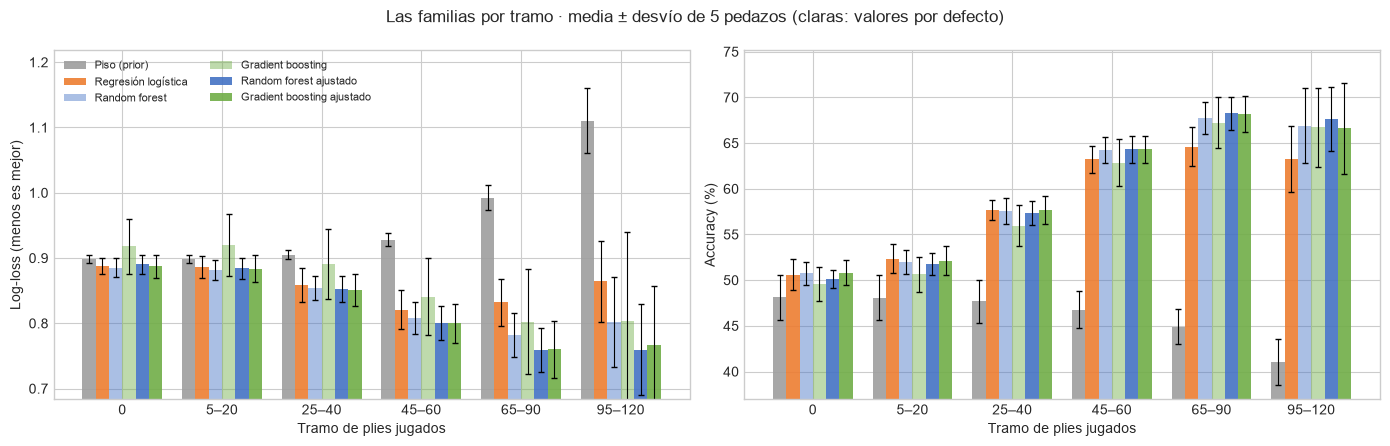

In [4]:
by_band = metricas_por_pedazo(pred, "tramo")
summary_band = media_y_desvio(by_band, "tramo")


def mean_sd(summary, metric, percent=False):
    scale, fmt = (100, "{:.1f} ± {:.1f}") if percent else (1, "{:.4f} ± {:.4f}")
    cells = [fmt.format(scale * m, scale * s) for m, s in zip(summary[metric], summary[f"± {metric}"])]
    return pd.Series(cells, index=summary.index).unstack("modelo")[MODELS].loc[TRAMOS]


for metric, percent in [("log_loss", False), ("accuracy", True), ("f1_macro", False), ("recall_empate", True)]:
    print(f"{metric} por tramo (media ± desvío de los 5 pedazos{', en %' if percent else ''})")
    display(mean_sd(summary_band, metric, percent))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(TRAMOS))
width = 0.8 / len(MODELS)
for ax, metric, ylabel, scale in [(axes[0], "log_loss", "Log-loss (menos es mejor)", 1),
                                  (axes[1], "accuracy", "Accuracy (%)", 100)]:
    for k, name in enumerate(MODELS):
        s = summary_band.loc[name].loc[TRAMOS]
        ax.bar(x + (k - (len(MODELS) - 1) / 2) * width, s[metric] * scale, width, yerr=s[f"± {metric}"] * scale,
               color=STYLE[name]["color"], alpha=0.45 if STYLE[name]["linestyle"] == "--" else 0.9,
               label=name, capsize=2, error_kw={"linewidth": 0.8})
    ax.set(xticks=x, xticklabels=TRAMOS, xlabel="Tramo de plies jugados", ylabel=ylabel)
    low = min(summary_band[metric].min() * scale * 0.9, ax.get_ylim()[1])
    ax.set_ylim(bottom=low)
axes[0].legend(fontsize=8, ncols=2)
fig.suptitle("Las familias por tramo · media ± desvío de 5 pedazos (claras: valores por defecto)")
plt.tight_layout()
plt.show()

**Lectura.** Las familias están más cerca antes de mover: en el tramo 0, salvo el boosting por defecto, todas quedan entre 0,8853 y 0,8903 de log-loss y entre 50,1 % y 50,8 % de accuracy. Están más lejos entre los plies 65 y 90: la logística da 0,8320 y el bosque ajustado 0,7593, 3,7 puntos menos de accuracy (64,6 % contra 68,3 %).

El orden de la tabla del 04 (bosque, logística, piso) se repite en log-loss en los seis tramos con el bosque por defecto. El boosting por defecto es el que cambia de lugar: peor que la logística hasta el ply 60 y mejor desde el 65. El bosque ajustado queda apenas detrás de la logística sólo en el tramo 0.

El boosting por defecto es el que más tablas reconoce: 11,3 % de recall entre los plies 65 y 90 y 22,3 % entre el 95 y el 120, y por eso tiene el F1 macro más alto (0,5855 al final). Lo paga en log-loss: 0,8032 ± 0,1370 en el último tramo, contra 0,7593 ± 0,0697 del bosque ajustado. Elige tablas más seguido, pero sus probabilidades son peores y más inestables. Entre los ajustados, el boosting reconoce 18,6 % de las tablas del último tramo y el bosque 10,6 %, con log-loss que no se distinguen.


## 5 · ¿Cambia la elección en algún tramo?

Las mismas tres comparaciones que decidieron el modelo en el 04, ahora tramo por tramo, cada una pedazo a pedazo:

1. **Cada ensamble por defecto contra la logística** (la regla de la §3: ¿vale la pena un modelo más complejo?).
2. **El boosting ajustado contra el bosque ajustado** (la regla de la §5: ¿bosque o boosting?).
3. **El elegido, ajustado, contra la logística**: cuánto suma el modelo complejo en cada momento de la partida.

En log-loss, una diferencia negativa es mejor; en accuracy, positiva. "le gana" y "pierde" aplican la regla: la diferencia media supera su desvío. Si en algún tramo gana otra familia, se informa: el modelo no cambia, porque se eligió con la métrica declarada sobre toda la partida, que es como lo usa la app.

Diferencia en log-loss, pedazo a pedazo


comparación,Random forest − Regresión logística,Gradient boosting − Regresión logística,Gradient boosting ajustado − Random forest ajustado,Random forest ajustado − Regresión logística
tramo,,,,
0,-0.0021 ± 0.0036,+0.0303 ± 0.0314,-0.0030 ± 0.0051,+0.0030 ± 0.0042
5–20,-0.0050 ± 0.0049,+0.0333 ± 0.0323,-0.0008 ± 0.0057,-0.0022 ± 0.0037
25–40,-0.0049 ± 0.0111,+0.0323 ± 0.0287,-0.0015 ± 0.0057,-0.0063 ± 0.0086
45–60,-0.0125 ± 0.0079,+0.0197 ± 0.0307,-0.0005 ± 0.0072,-0.0205 ± 0.0077
65–90,-0.0495 ± 0.0068,-0.0298 ± 0.0465,+0.0011 ± 0.0126,-0.0727 ± 0.0075
95–120,-0.0620 ± 0.0159,-0.0611 ± 0.0748,+0.0067 ± 0.0233,-0.1050 ± 0.0106
toda la partida,-0.0184 ± 0.0058,+0.0117 ± 0.0370,-0.0003 ± 0.0081,-0.0265 ± 0.0039


comparación,Random forest − Regresión logística,Gradient boosting − Regresión logística,Gradient boosting ajustado − Random forest ajustado,Random forest ajustado − Regresión logística
tramo,,,,
0,no se distingue,no se distingue,no se distingue,no se distingue
5–20,le gana,pierde,no se distingue,no se distingue
25–40,no se distingue,pierde,no se distingue,no se distingue
45–60,le gana,no se distingue,no se distingue,le gana
65–90,le gana,no se distingue,no se distingue,le gana
95–120,le gana,no se distingue,no se distingue,le gana
toda la partida,le gana,no se distingue,no se distingue,le gana


Diferencia en puntos de accuracy, pedazo a pedazo


comparación,Random forest − Regresión logística,Gradient boosting − Regresión logística,Gradient boosting ajustado − Random forest ajustado,Random forest ajustado − Regresión logística
tramo,,,,
0,+0.1 ± 1.1,-1.0 ± 1.5,+0.7 ± 1.4,-0.5 ± 2.0
5–20,-0.4 ± 0.5,-1.7 ± 1.3,+0.3 ± 1.1,-0.6 ± 1.3
25–40,-0.1 ± 0.6,-1.7 ± 1.2,+0.3 ± 0.6,-0.3 ± 0.4
45–60,+1.0 ± 0.4,-0.4 ± 1.2,+0.0 ± 0.3,+1.1 ± 0.6
65–90,+3.2 ± 0.5,+2.6 ± 0.9,-0.1 ± 0.5,+3.7 ± 0.5
95–120,+3.6 ± 1.0,+3.4 ± 0.8,-1.0 ± 1.8,+4.3 ± 0.4
toda la partida,+0.9 ± 0.2,-0.3 ± 0.9,+0.1 ± 0.6,+0.9 ± 0.4


comparación,Random forest − Regresión logística,Gradient boosting − Regresión logística,Gradient boosting ajustado − Random forest ajustado,Random forest ajustado − Regresión logística
tramo,,,,
0,no se distingue,no se distingue,no se distingue,no se distingue
5–20,no se distingue,pierde,no se distingue,no se distingue
25–40,no se distingue,pierde,no se distingue,no se distingue
45–60,le gana,no se distingue,no se distingue,le gana
65–90,le gana,le gana,no se distingue,le gana
95–120,le gana,le gana,no se distingue,le gana
toda la partida,le gana,no se distingue,no se distingue,le gana


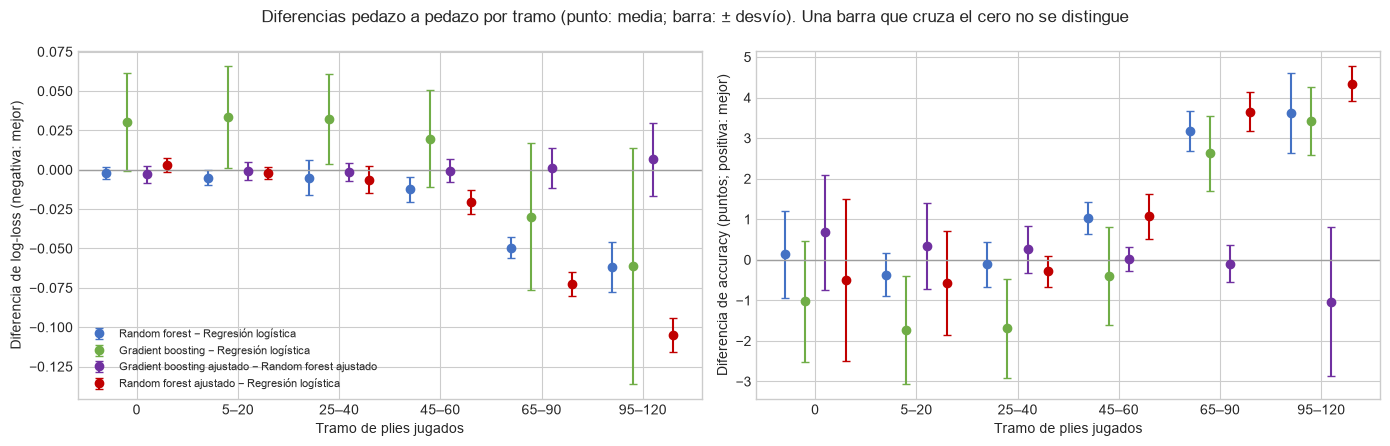

In [5]:
chosen_tuned = f"{CHOSEN} ajustado"
other_tuned = next(name for name in TUNED if name != chosen_tuned)
comparisons = [
    *[(name, SIMPLE) for name in DEFAULTS],
    (other_tuned, chosen_tuned),
    (chosen_tuned, SIMPLE),
]
diffs = pd.concat([diferencia_pareada(by_band, model, reference, "tramo") for model, reference in comparisons]
                  + [diferencia_pareada(overall, model, reference).assign(tramo="toda la partida")
                     for model, reference in comparisons], ignore_index=True)
diffs["comparación"] = diffs["modelo"] + " − " + diffs["referencia"]
diffs["veredicto"] = np.select([diffs["le gana"], diffs["pierde"]], ["le gana", "pierde"], default="no se distingue")
order = TRAMOS + ["toda la partida"]
labels = [f"{m} − {r}" for m, r in comparisons]
for metric, scale, unit in [("log_loss", 1, "log-loss"), ("accuracy", 100, "puntos de accuracy")]:
    d = diffs[diffs["metrica"] == metric].copy()
    d["diferencia (± desvío)"] = [f"{scale * m:+.4f} ± {scale * s:.4f}" if scale == 1 else f"{scale * m:+.1f} ± {scale * s:.1f}"
                                  for m, s in zip(d["diferencia"], d["± diferencia"])]
    print(f"Diferencia en {unit}, pedazo a pedazo")
    display(d.pivot(index="tramo", columns="comparación", values="diferencia (± desvío)").loc[order, labels])
    display(d.pivot(index="tramo", columns="comparación", values="veredicto").loc[order, labels])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(TRAMOS))
width = 0.8 / len(labels)
colors = ["#4472c4", "#70ad47", "#7030a0", "#c00000"]
for ax, metric, ylabel, scale in [(axes[0], "log_loss", "Diferencia de log-loss (negativa: mejor)", 1),
                                  (axes[1], "accuracy", "Diferencia de accuracy (puntos; positiva: mejor)", 100)]:
    for k, (label, color) in enumerate(zip(labels, colors)):
        d = diffs[(diffs["metrica"] == metric) & (diffs["comparación"] == label)].set_index("tramo").loc[TRAMOS]
        ax.errorbar(x + (k - (len(labels) - 1) / 2) * width, d["diferencia"] * scale, yerr=d["± diferencia"] * scale,
                    fmt="o", color=color, capsize=3, label=label)
    ax.axhline(0, color="#9e9e9e", linewidth=1)
    ax.set(xticks=x, xticklabels=TRAMOS, xlabel="Tramo de plies jugados", ylabel=ylabel)
axes[0].legend(fontsize=8)
fig.suptitle("Diferencias pedazo a pedazo por tramo (punto: media; barra: ± desvío). Una barra que cruza el cero no se distingue")
plt.tight_layout()
plt.show()

**Lectura.**

- **Ensamble contra logística.** El bosque por defecto le gana en log-loss en cuatro de los seis tramos (5–20, 45–60, 65–90 y 95–120), y la ventaja crece de −0,0050 a −0,0620. En el tramo 0 (−0,0021 ± 0,0036) y entre los plies 25 y 40 no se distingue. En accuracy le gana recién desde el ply 45: +1,0, +3,2 y +3,6 puntos. El bosque ajustado repite el patrón con más claridad: no se distingue de la logística hasta el ply 40 (en el tramo 0 queda +0,0030 ± 0,0042, apenas peor y dentro de la variación). Desde el 45 le gana en las dos métricas: −0,0205, −0,0727 y −0,1050 de log-loss, y +1,1, +3,7 y +4,3 puntos de accuracy. Lo que suma un modelo más complejo está en el medio juego y el final, que es donde hay posición para leer. El boosting por defecto pierde contra la logística en log-loss entre los plies 5 y 40.
- **Bosque contra boosting, ajustados.** No se distinguen en ningún tramo ni en ninguna de las dos métricas. El boosting queda levemente adelante al principio (−0,0030 ± 0,0051 en el tramo 0) y el bosque al final (+0,0067 ± 0,0233 entre los plies 95 y 120), pero siempre dentro del desvío. Es el mismo empate de la §5 del 04 (−0,0003 ± 0,0081), tramo por tramo.
- **La elección no cambiaría en ningún tramo.** Ninguna familia le gana al bosque ajustado por más que el desvío en ningún momento de la partida. Donde no le gana a la logística (hasta el ply 40) tampoco pierde. Además la app usa un solo modelo para toda la partida y se eligió con la log-loss sobre todos los cortes. Cambiar de familia según el tramo sería volver a elegir con estos mismos datos, y no hay un tramo que lo justifique.


## 6 · Verificación

Los controles que sostienen las tablas de arriba:

- el archivo reproduce la comparación del 04 (ya se comprobó en la sección 2);
- todas las familias predicen las mismas filas, una vez cada una por pedazo;
- las probabilidades de cada fila suman 1;
- las filas de los cortes y de los tramos suman las de cada pedazo;
- un modelo contra sí mismo no tiene diferencia.

In [6]:
n_models = len(MODELS)
assert not pred.duplicated(["modelo", "fold", "GameUrl", "corte_ply"]).any(), "Una fila repetida en un pedazo"
assert np.allclose(pred[["p_empate", "p_blancas", "p_negras"]].sum(axis=1), 1, atol=1e-6), "Probabilidades que no suman 1"
rows_per_fold = overall.set_index(["modelo", "fold"])["filas"].sort_index()
for table in (by_cut, by_band):
    assert table.groupby(["modelo", "fold"])["filas"].sum().sort_index().equals(rows_per_fold), "Los grupos no suman las filas del pedazo"
assert len(summary_band) == n_models * len(TRAMOS), "Falta algún (modelo, tramo)"
itself = diferencia_pareada(by_band, SIMPLE, SIMPLE, "tramo")
assert (itself["diferencia"] == 0).all() and not itself["le gana"].any()
print("Verificación OK")

Verificación OK


## 7 · Conclusiones

- **En toda la partida** se repite lo del 04: el bosque ajustado y el boosting ajustado se empatan (−0,0003 ± 0,0081), y el bosque ajustado le gana a la logística (−0,0265 ± 0,0039 de log-loss, +0,9 ± 0,4 puntos de accuracy).
- **Antes de mover y en la apertura (hasta el ply 40) las familias no se distinguen.** Todas quedan apenas por encima del piso (en el corte 0, 1 % menos de log-loss y unos 2,5 puntos de accuracy). El modelo complejo no suma nada que el rating y el contexto no le den también a una logística.
- **Desde el ply 45 el bosque se separa de la logística** en las dos métricas, y la distancia crece hasta el final: −0,1050 de log-loss y +4,3 puntos de accuracy entre los plies 95 y 120. La logística empeora en las partidas largas; el bosque no.
- **El boosting por defecto** es el que más tablas reconoce (22,3 % al final), pero con peor log-loss y mucha más variación entre pedazos; antes del ply 40 pierde contra la logística.
- **La elección no cambia:** en ningún tramo otra familia le gana al bosque ajustado por más que el desvío. El modelo se eligió con la log-loss sobre toda la partida, que es como lo usa la app, y este desglose lo respalda: la ventaja del bosque está en el medio juego y el final, y antes de eso ninguna familia es mejor.
- **Limitación:** son cinco pedazos del 25 % de las partidas de train, con las columnas base. Al final quedan pocas partidas por pedazo y las bandas se ensanchan, así que las diferencias del último tramo tienen más incertidumbre que las del medio juego.
